<a href="https://colab.research.google.com/github/Niha5019/MLA0201-FOML/blob/main/EXP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Specific boundary S: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
General boundary G: [['?', '?', '?', '?', '?', '?']]
Specific boundary S: ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
General boundary G: [['?', '?', '?', '?', '?', '?']]
Specific boundary S: ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
General boundary G: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]
Specific boundary S: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
General boundary G: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]


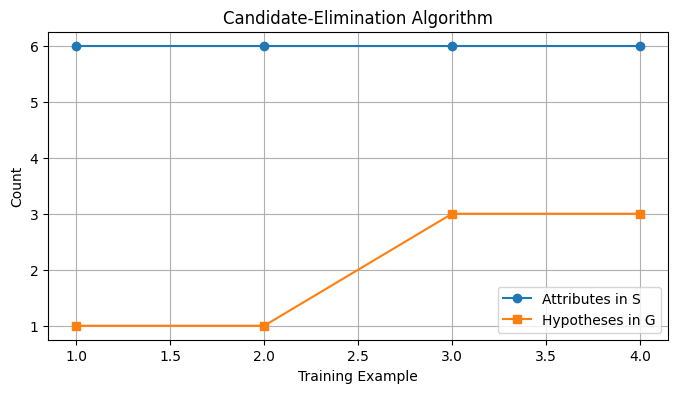

In [3]:
import csv
import matplotlib.pyplot as plt

# Sample dataset to write to training.csv if it does not exist
csv_content = [
    ["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast", "EnjoySport"],
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
    ["Sunny", "Warm", "High", "Strong", "Warm", "Same", "Yes"],
    ["Rainy", "Cold", "High", "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High", "Strong", "Cool", "Change", "Yes"]
]

# Create the file
with open("training.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerows(csv_content)

# Read training data from CSV
with open("training.csv", "r") as f:
    data = list(csv.reader(f))

    data = data[1:]  # Skip header
    S = ['0'] * (len(data[0]) - 1)
    G = [['?' for _ in S]]

    history = []

    for row in data:
        x, target = row[:-1], row[-1]

        if target.lower() == "yes":
            for i in range(len(S)):
                if S[i] == '0':
                    S[i] = x[i]
                elif S[i] != x[i]:
                    S[i] = '?'

            G = [g for g in G if all(
                g[i] == '?' or S[i] == '?' or g[i] == S[i]
                for i in range(len(S))
            )]
        else:
            new_G = []
            for g in G:
                for i in range(len(S)):
                    if g[i] == '?' and S[i] not in ('?', '0') and S[i] != x[i]:
                        h = g.copy()
                        h[i] = S[i]
                        new_G.append(h)
            G = new_G

        history.append((str(S.copy()), len(G)))

        print("Specific boundary S:", S)
        print("General boundary G:", G)

    # Graph of hypothesis changes
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(history) + 1),
             [len(S.split(',')) for S, _ in history],
             marker='o', label='Attributes in S')
    plt.plot(range(1, len(history) + 1),
             [g for _, g in history],
             marker='s', label='Hypotheses in G')

    plt.xlabel("Training Example")
    plt.ylabel("Count")
    plt.title("Candidate-Elimination Algorithm")
    plt.legend()
    plt.grid(True)
    plt.show()
